In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
df = pd.read_csv("./bee_data.csv")
print(df.head(5))
img_dir = "./bee_imgs/bee_imgs/"

          file     date   time        location  zip code subspecies  \
0  041_066.png  8/28/18  16:07  Alvin, TX, USA     77511         -1   
1  041_072.png  8/28/18  16:07  Alvin, TX, USA     77511         -1   
2  041_073.png  8/28/18  16:07  Alvin, TX, USA     77511         -1   
3  041_067.png  8/28/18  16:07  Alvin, TX, USA     77511         -1   
4  041_059.png  8/28/18  16:07  Alvin, TX, USA     77511         -1   

              health  pollen_carrying   caste  
0  hive being robbed            False  worker  
1  hive being robbed            False  worker  
2  hive being robbed            False  worker  
3  hive being robbed            False  worker  
4  hive being robbed            False  worker  


In [ ]:
le = LabelEncoder()
df["label"] = le.fit_transform(df["health"]) # sağlık durumu etiketlerini 0 1 2 3 gibi ekliyoruz

print("Sınıflar")
for i, sinif_adi in enumerate(le.classes_):
    print(f"{sinif_adi} -> {i}")

Sınıflar
Varroa, Small Hive Beetles -> 0
ant problems -> 1
few varrao, hive beetles -> 2
healthy -> 3
hive being robbed -> 4
missing queen -> 5


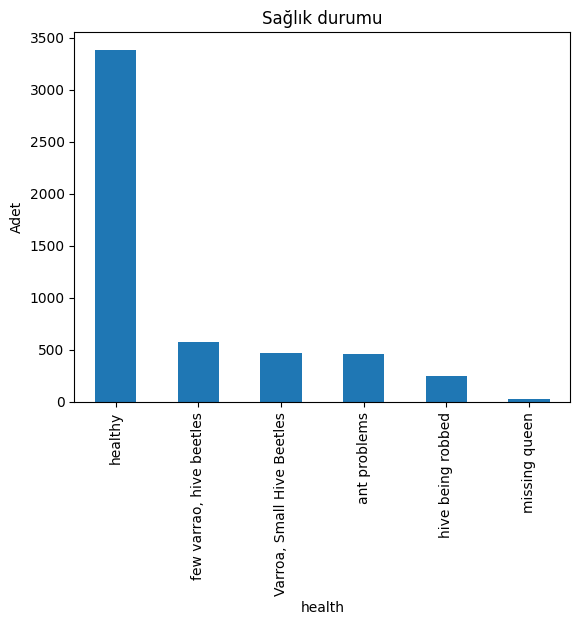

In [ ]:
df['health'].value_counts().plot(kind='bar')
plt.title("Sağlık durumu")
plt.ylabel("Adet")
plt.show()

In [ ]:
samples = df.groupby("health").sample(1)

for index, row in samples.iterrows():

    img = Image.open(os.path.join(img_dir, row["file"]))

    plt.figure(figsize=(2,2))
    plt.imshow(img)
    plt.title(f"indeks: {index}, sağlık durumu: {row['health']}")
    plt.axis("off")
    plt.show()

FileNotFoundError: [Errno 2] No such file or directory: './bee_imgs/bee_imgs/038_068.png'

In [ ]:
RESIM_BOYUTU = (224,224)

def gorsel_on_isleme(img):
    img = img.resize(RESIM_BOYUTU) #RESIZING
    return img


def gorsel_hazirla(resim_dizini):
    img = Image.open(resim_dizini).convert("RGB")
    img = gorsel_on_isleme(img)
    return img

Silinebilir Alan

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],
                         [0.229,0.224,0.225])
])


class BeeDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(os.path.join(self.img_dir, row["file"])).convert("RGB")
        img = gorsel_on_isleme(img)

        if self.transform:
            img = self.transform(img)

        return img, row["label"]




In [ ]:

train_df, test_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:

# =====================
# 10-FOLD CV (TRAIN ONLY)
# =====================
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

fold_accuracies = []


for fold, (train_idx, val_idx) in enumerate(skf.split(train_df, train_df["label"])):
    print(f"\n===== FOLD {fold+1} =====")
    fold_train = train_df.iloc[train_idx]
    fold_val   = train_df.iloc[val_idx]

    train_loader = DataLoader(BeeDataset(fold_train, img_dir, transform), batch_size=32, shuffle=True)
    val_loader   = DataLoader(BeeDataset(fold_val, img_dir, transform), batch_size=32)

    model = models.resnet18(weights="DEFAULT")
    model.fc = nn.Linear(model.fc.in_features, len(le.classes_))
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    # TRAIN
    for epoch in range(20):
        model.train()
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

    # VALIDATION
    model.eval()
    preds, targets = [], []

    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs = imgs.to(device)
            outputs = model(imgs)

            _, predicted = torch.max(outputs, 1)

            preds.extend(predicted.cpu().numpy())
            targets.extend(labels.numpy())

    acc = accuracy_score(targets, preds)
    fold_accuracies.append(acc)

    print(f"Fold Accuracy: {acc:.4f}")

In [ ]:
print("\n===== 10-FOLD CV RESULT =====")
print(f"Mean Accuracy: {np.mean(fold_accuracies):.4f}")

In [ ]:
test_loader = DataLoader(BeeDataset(test_df, img_dir, transform), batch_size=32)

model.eval()
preds, targets = [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)

        _, predicted = torch.max(outputs, 1)

        preds.extend(predicted.cpu().numpy())
        targets.extend(labels.numpy())

accuracy = accuracy_score(targets, preds)
print("\n===== FINAL TEST RESULT =====")
print("Test Accuracy:", accuracy)

In [ ]:
disp = ConfusionMatrixDisplay.from_predictions(
    targets,
    preds,
    display_labels=le.classes_,
    normalize="true"
)

plt.xticks(rotation=90)
plt.title("Test Confusion Matrix")
plt.show()

In [ ]:

accuracy = accuracy_score(targets, preds)
precision = precision_score(targets, preds, average='macro')
recall    = recall_score(targets, preds, average='macro')
f1        = f1_score(targets, preds, average='macro')

print("\n===== FINAL METRICS =====")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:\n")
print(classification_report(targets, preds, target_names=le.classes_))